# T1 Analysis



<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Import Libraries</h2>
</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from scipy.optimize import curve_fit

<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;"> General Helpful Functions</h2>
</div>

In [22]:
def load_run(run_folder):
    data = np.load(run_folder / "t1_mwref_data.npz")
    with open(run_folder / "metadata.json") as f:
        metadata = json.load(f)

    skip_keys = {"experiment_id", "timestamp"}  # don't need these
    run = {k: v for k, v in metadata.items() if k not in skip_keys}

    run["delay_us"] = data["delay_us"]
    run["signal1"] = data["signal1"]
    run["signal2"] = data["signal2"]
    run["reference1"] = data["reference1"]
    run["reference2"] = data["reference2"]
    run["run_folder"] = run_folder
    return run

def load_all_runs(parent_dirs):
    '''
    parent_dirs: list of (directory, tag) or (directory, tag, run_numbers) tuples.
        run_numbers is an optional list of ints to restrict which runs get loaded
        from that directory (e.g. [1, 4, 5]); omit or pass None to load all.
    keys runs by folder name (timestamp) so runs from different directories never collide
    '''
    runs = {}
    for entry in parent_dirs:
        parent_dir, tag = entry[0], entry[1]
        run_numbers = entry[2] if len(entry) > 2 else None

        parent_dir = Path(parent_dir)
        for run_folder in sorted(parent_dir.iterdir()):
            if not run_folder.is_dir():
                continue
            if not (run_folder / "t1_mwref_data.npz").exists():
                continue

            run_number = int(run_folder.name.split("_")[-1])
            if run_numbers is not None and run_number not in run_numbers:
                continue

            run = load_run(run_folder)
            run["tag"] = tag
            runs[run_folder.name] = run
    return runs


def run_diff_and_err(run):
    diff = run["signal1"] - run["signal2"]
    err = np.full_like(diff, np.std(run["reference1"] - run["reference2"]))  # empirical noise, scales with each run's own reps
    return diff, err

def decay(t, A, T1):
    return A * np.exp(-t / T1)  # S1 - S2 model

def plot_runs(run_keys, readouts=('signal1', 'signal2', 'reference1', 'reference2'), xlim=None, ylim=None):
    '''
    run_keys: list of keys into `runs` to overlay
    readouts: which of 'signal1', 'signal2', 'reference1', 'reference2' to show
    xlim, ylim: optional (min, max) tuples
    '''
    styles = {'signal1': 'o-', 'signal2': 'o-', 'reference1': 's--', 'reference2': 's--'}

    for key in run_keys:
        run = runs[key]
        t = run["delay_us"]
        for readout in readouts:
            plt.plot(t, run[readout], styles[readout], label=f"{readout} ({key}, {run['tag']})")

    plt.xlabel('delay (us)')
    plt.ylabel('counts')
    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)
    plt.legend(fontsize=7)
    plt.show()

def plot_diffs(run_keys, xlim=None, ylim=None):
    '''
    run_keys: list of keys into `runs` to overlay as signal1-signal2 difference curves
    xlim, ylim: optional (min, max) tuples
    '''
    for key in run_keys:
        run = runs[key]
        t = run["delay_us"]
        diff = run["signal1"] - run["signal2"]
        err = np.full_like(diff, np.std(run["reference1"] - run["reference2"]))
        plt.errorbar(t, diff, yerr=err, fmt='o', capsize=3, label=f"{key} ({run['tag']})")

    plt.axhline(0, color='gray', lw=0.8)
    plt.xlabel('delay (us)')
    plt.ylabel('signal1 - signal2 (counts)')
    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)
    plt.legend(fontsize=7)
    plt.show()

<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Load Data</h2>
</div>

In [44]:
runs = load_all_runs([
    ("/Volumes/hlab-nas/Data/DefectMsmts/Data/Albania/T1_MWref", "forward", [31,37]),
    ("/Volumes/hlab-nas/Data/DefectMsmts/Data/Albania/T1_MWref_reverse", "reverse",[4,5]),
])
print(list(runs.keys()))

['20260929144357_031', '20261010104409_037', '20261014113907_004', '20261014222404_005']


<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Plotting</h2>
</div>

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Plot Raw Data</h3>
</div>


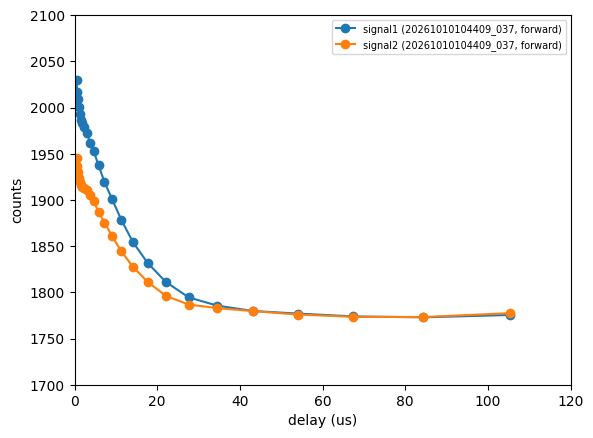

In [72]:
plot_runs(['20261010104409_037'], readouts=['signal1', 'signal2'], xlim=(0, 120),ylim=(1700, 2100))

In [94]:
run_key1 = "20261010104409_037"   # pick from list(runs.keys())
with open(runs[run_key1]["run_folder"] / "metadata.json") as f:
    metadata = json.load(f)

for k, v in metadata.items():
    print(f"{k}: {v}")



run_key2 = "20260929144357_031"   # pick from list(runs.keys())
with open(runs[run_key2]["run_folder"] / "metadata.json") as f:
    metadata = json.load(f)

for k, v in metadata.items():
    print(f"{k}: {v}")

experiment_id: 20261010104409_037
timestamp: 2026-10-10T10:44:09.903215
laser_power: 30
mw_gain: 7000
resonance_fMHz: 3429
mw_pulse_tns: 3000
reps: 129600000
delay_start_tus: 0.5
delay_stop_tus: 100
scaling_factor: 5/4
relax_delay_treg: 400
laser_on_tus: 15.0
readout_integration_tns: 48.828125
readout_reference_start_tns: 10000.0
mw_readout_delay_treg: 35
laser_readout_offset_treg: 140
experiment_id: 20260929144357_031
timestamp: 2026-09-29T14:43:57.129942
laser_power: 50
mw_gain: 7000
resonance_fMHz: 3510
mw_pulse_tns: 3000
reps: 1000000
delay_start_tus: 0.5
delay_stop_tus: 100
scaling_factor: 5/4
relax_delay_treg: 400
laser_on_tus: 15.0
readout_integration_tns: 48.828125
readout_reference_start_tns: 10000.0
mw_readout_delay_treg: 35
laser_readout_offset_treg: 140


<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Plot T1 Signal</h3>
</div>


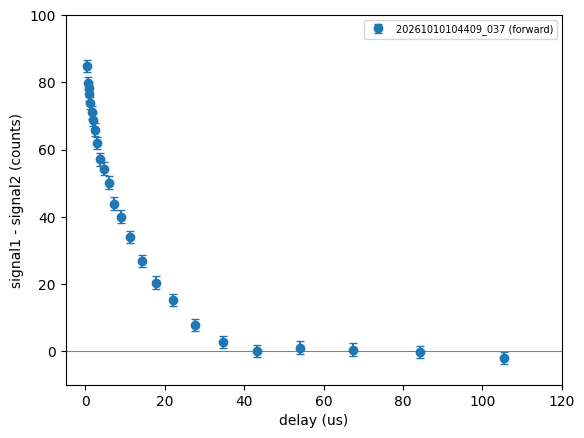

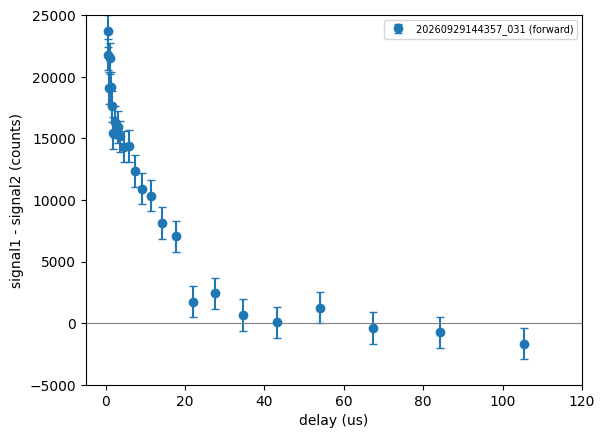

In [92]:
run_key1 = "20261010104409_037" 
run_key2 = "20260929144357_031" 
plot_diffs([run_key1], xlim=(-5, 120), ylim=(-10, 100))
plot_diffs([run_key2], xlim=(-5, 120), ylim=(-5000, 25000))

In [41]:
run_rev = runs["20261014222404_005"]
t_rev = run_rev["delay_us"]
diff_rev = run_rev["signal1"] - run_rev["signal2"]
err_rev = np.full_like(diff_rev, np.std(run_rev["reference1"] - run_rev["reference2"]))

diff_fwd_interp = np.interp(t_rev, t_fwd, diff_fwd)

residual = diff_rev - diff_fwd_interp
chi2 = np.sum((residual / err_rev)**2)
dof = len(t_rev)
print(f"reduced chi2 (run 005 vs forward curve): {chi2/dof:.2f}")

reduced chi2 (run 005 vs forward curve): 0.96


In [42]:
run4 = runs["20261014113907_004"]
run5 = runs["20261014222404_005"]

# inverse-variance weighted combination (both reverse runs, same delay values)
diff4, diff5 = run4["signal1"] - run4["signal2"], run5["signal1"] - run5["signal2"]
err4 = np.std(run4["reference1"] - run4["reference2"])
err5 = np.std(run5["reference1"] - run5["reference2"])

w4, w5 = 1/err4**2, 1/err5**2
diff_combined = (diff4*w4 + diff5*w5) / (w4 + w5)
err_combined = np.sqrt(1 / (w4 + w5))

t_combined = run4["delay_us"]  # both reverse runs should share the same delay points

diff_fwd_interp = np.interp(t_combined, t_fwd, diff_fwd)
residual = diff_combined - diff_fwd_interp
chi2 = np.sum((residual / err_combined)**2)
print(f"combined reverse noise sigma: {err_combined:.2f}")
print(f"reduced chi2 (combined reverse vs forward curve): {chi2/len(t_combined):.2f}")

combined reverse noise sigma: 2.91
reduced chi2 (combined reverse vs forward curve): 1.81


In [43]:
np.allclose(run4["delay_us"], run5["delay_us"])

True

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Plot Fit</h3>
</div>


A  = 82 ± 1 counts
T1 = 11.9 ± 0.3 us


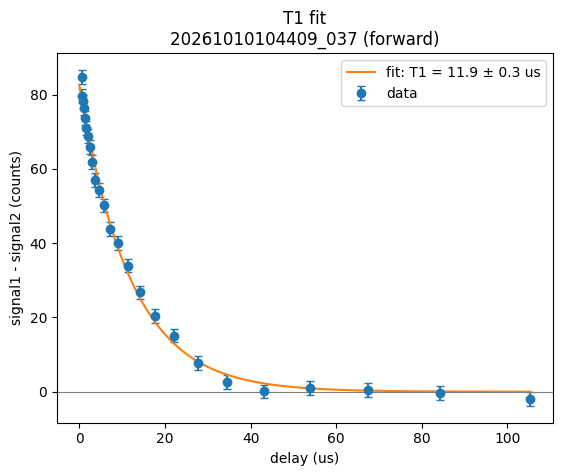

chi2/dof = 1.19
C = -0.6 ± 0.8 counts
T1 (free offset) = 12.2 ± 0.4 us


In [95]:
run_key = "20261010104409_037"   # pick from list(runs.keys())
run = runs[run_key]

t = run["delay_us"]
diff, err = run_diff_and_err(run)
run_name = f"{run_key} ({run['tag']})"

popt, pcov = curve_fit(decay, t, diff, p0=[diff.max(), 10], sigma=err, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
print(f"A  = {popt[0]:.0f} ± {perr[0]:.0f} counts")
print(f"T1 = {popt[1]:.1f} ± {perr[1]:.1f} us")

tt = np.linspace(0, t.max(), 500)
plt.errorbar(t, diff, yerr=err, fmt='o', capsize=3, label='data')
plt.plot(tt, decay(tt, *popt), '-', label=f'fit: T1 = {popt[1]:.1f} ± {perr[1]:.1f} us')
plt.axhline(0, color='gray', lw=0.8)
plt.xlabel('delay (us)')
plt.ylabel('signal1 - signal2 (counts)')
plt.title(f"T1 fit\n{run_name}")
plt.legend()
plt.show()

dof = len(t) - len(popt)  # 2 free params: A, T1
chi2 = np.sum(((diff - decay(t, *popt)) / err)**2)
print(f"chi2/dof = {chi2/dof:.2f}")

def decay_offset(t, A, T1, C):
    return A * np.exp(-t / T1) + C

popt2, pcov2 = curve_fit(decay_offset, t, diff, p0=[diff.max(), 10, 0], sigma=err, absolute_sigma=True)
perr2 = np.sqrt(np.diag(pcov2))
print(f"C = {popt2[2]:.1f} ± {perr2[2]:.1f} counts")  # if ~0 within error, zero-asymptote model is fine
print(f"T1 (free offset) = {popt2[1]:.1f} ± {perr2[1]:.1f} us")  # compare to your original T1